# Lab 5 – Autonomous Driving using Q-Learning
**Reinforcement Learning Application Exploration and Performance Analysis**

**Application:** Autonomous Driving (multi-lane highway driving with traffic)  
**Algorithm:** Tabular Q-Learning (off-policy temporal-difference control)  
**Libraries:** Python 3, NumPy, Matplotlib only (the driving environment is written from scratch – no external RL library is used)

---
## 1. Objective
Explore an application-oriented RL problem, formulate it with the standard RL components (agent, environment, state, action, reward, terminal condition), train a Q-Learning agent and analyse its performance.

**Application / domain.** Autonomous driving. A self-driving car on a 3-lane highway must keep moving forward quickly while sharing the road with slower vehicles. It has to decide when to accelerate, brake, or change lane so that it never collides, keeps a safe following distance and does not waste time stuck behind slow traffic.

**Problem to be solved.** In every episode the ego car (the learning agent) drives for 200 time-steps through randomly generated traffic. Slow cars (speed 1 or 2 cells/step) keep appearing ahead in the three lanes. The agent has to reach the end of the episode without crashing while making as much forward progress as possible.

**Objective of the RL agent.** Learn a policy π(s) that maximises the expected discounted return: drive fast, overtake slow traffic by changing lanes, keep a safe gap, avoid unnecessary lane changes and – above all – avoid collisions.

## 2. RL Problem Formulation
The task is modelled as a finite, episodic, **stochastic** Markov Decision Process ⟨S, A, P, R, γ⟩.

| Component | Description |
|---|---|
| **Agent** | The ego car's driving controller (Q-Learning agent). It observes the traffic around it and chooses one driving manoeuvre per time-step. |
| **Environment** | A custom 3-lane highway simulator (`HighwayEnv`). Other cars spawn at random ahead of the ego car in random lanes with speed 1 or 2 cells/step. The environment applies the action, moves all vehicles, checks collisions and returns the next state and reward. |
| **State space** | Discrete, \|S\| = 768, built from: ego lane (3) × ego speed level (4: stopped/slow/medium/fast) × distance bucket to the nearest car ahead **in each of the 3 lanes** (4 buckets each: *critical* ≤1 cell, *near* 2-3, *medium* 4-6, *free* ≥7). 3 × 4 × 4 × 4 × 4 = 768 |
| **Action space** | Discrete, \|A\| = 5: 0 – keep lane & speed, 1 – accelerate, 2 – brake, 3 – change lane left, 4 – change lane right |
| **Reward function** | +0.5 × speed per step (progress: 0 / 0.5 / 1.0 / 1.5)  \n −1 when driving (speed > 0) at an unsafe gap (≤1 cell) behind a car  \n −0.2 for every lane change (comfort)  \n −5 for steering off the road (illegal lane change)  \n −50 for a collision |
| **Terminal condition** | *Termination:* collision with another vehicle (failure).  \n *Truncation:* the episode ends after 200 steps – reaching it without a crash counts as **success**. |
| **Discount factor** | γ = 0.95 |

In [1]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, FancyBboxPatch
import os, time

os.makedirs("figures", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print("NumPy", np.__version__, "| Matplotlib", matplotlib.__version__)

NumPy 2.4.4 | Matplotlib 3.10.8


## 3. Environment implementation
The simulator is deliberately simple but captures the core difficulties of driving: delayed consequences (a collision happens several steps after a bad decision), a trade-off between speed and safety, and random traffic.

* The ego car moves `v ∈ {0,1,2,3}` cells per step (0 = stopped, so it can always fall back and let slow traffic clear); other cars move 1 or 2 cells per step, so the ego car catches up with them and must overtake or slow down.
* Positions are integers on a 1-D road with 3 lanes. The agent never sees absolute positions – only the *relative* distance buckets, exactly as a real car perceives its surroundings with radar/LiDAR.
* A **collision** happens if the ego car reaches/passes a car in its own lane, or changes lane into a cell next to/occupied by another car.

In [2]:
class HighwayEnv:
    """3-lane highway driving environment (ego-centric, discrete)."""
    N_LANES, MAX_STEPS = 3, 200
    SPEEDS = (0, 1, 2, 3)                   # ego speed levels (cells / step); 0 = stopped
    N_ACTIONS = 5
    ACTION_NAMES = ["keep", "accelerate", "brake", "left", "right"]
    N_STATES = 3 * 4 * 4 * 4 * 4            # 768
    SPAWN_GAP, P_SPAWN = 12, 0.08           # new cars appear 12 cells ahead

    # reward constants
    R_PROGRESS, R_TAILGATE, R_LANE_CHANGE = 0.5, -1.0, -0.2
    R_OFFROAD, R_COLLISION = -5.0, -50.0

    def __init__(self, rng):
        self.rng = rng

    # ---------------------------------------------------------------- reset
    def reset(self):
        self.pos, self.t, self.v = 0, 0, 2
        self.lane = int(self.rng.integers(self.N_LANES))
        self.cars = []                                    # each car: [lane, position, speed]
        for l in range(self.N_LANES):                     # initial traffic
            p = int(self.rng.integers(5, 9))
            while p < 22:
                if self.rng.random() < 0.6:
                    self.cars.append([l, p, int(self.rng.integers(1, 3))])
                p += int(self.rng.integers(4, 8))
        self.stats = dict(overtakes=0, lane_changes=0, offroad=0, speed_sum=0, tailgate=0)
        return self._obs()

    # ----------------------------------------------------------- perception
    def _gap(self, lane):
        """distance to the nearest car ahead (or alongside) in `lane`; 99 if none"""
        g = [c[1] - self.pos for c in self.cars if c[0] == lane and c[1] - self.pos >= -1]
        return min(g) if g else 99

    def _obs(self):
        s = self.lane * 4 + self.v
        for l in range(self.N_LANES):
            g = self._gap(l)
            b = 0 if g <= 1 else 1 if g <= 3 else 2 if g <= 6 else 3
            s = s * 4 + b
        return s

    # ----------------------------------------------------------------- step
    def step(self, a):
        r, crashed = 0.0, False
        new_lane = self.lane
        if a in (3, 4):                                   # lane change
            new_lane = self.lane - 1 if a == 3 else self.lane + 1
            if not 0 <= new_lane < self.N_LANES:          # tried to leave the road
                r += self.R_OFFROAD; new_lane = self.lane; self.stats["offroad"] += 1
            else:
                r += self.R_LANE_CHANGE; self.stats["lane_changes"] += 1
                if any(c[0] == new_lane and abs(c[1] - self.pos) <= 1 for c in self.cars):
                    crashed = True                        # cut into another car
        if a == 1:   self.v = min(3, self.v + 1)
        elif a == 2: self.v = max(0, self.v - 1)

        old_pos, self.lane = self.pos, new_lane
        if not crashed:                                   # rear-end collision check
            for c in self.cars:
                if c[0] == self.lane and c[1] - old_pos > 0 and c[1] + c[2] - (old_pos + self.v) <= 0:
                    crashed = True
        self.pos += self.v
        for c in self.cars:                               # traffic moves
            c[1] += c[2]
        self.t += 1; self.stats["speed_sum"] += self.v

        if crashed:
            r += self.R_COLLISION
        else:
            r += self.R_PROGRESS * self.v
            if self.v > 0 and self._gap(self.lane) <= 1:     # unsafe following distance
                r += self.R_TAILGATE; self.stats["tailgate"] += 1

        n = len(self.cars)                                # remove cars left behind
        self.cars = [c for c in self.cars if c[1] - self.pos >= -2]
        self.stats["overtakes"] += n - len(self.cars)
        for l in range(self.N_LANES):                     # random new traffic
            if self.rng.random() < self.P_SPAWN and not any(
                    c[0] == l and c[1] - self.pos >= self.SPAWN_GAP - 4 for c in self.cars):
                self.cars.append([l, self.pos + self.SPAWN_GAP, int(self.rng.integers(1, 3))])

        terminated = crashed
        truncated = (self.t >= self.MAX_STEPS) and not crashed
        return self._obs(), r, terminated, truncated, {"crashed": crashed}

    def snapshot(self):
        return dict(lane=self.lane, v=self.v, t=self.t,
                    cars=[(c[0], c[1] - self.pos, c[2]) for c in self.cars])

### 3.1 Visualising the environment
The helper below draws the road from the ego car's point of view (the ego car is blue; other cars are orange = speed 1, red = speed 2). It is used for the environment screenshots, for the random-agent crash and later for the trained agent's manoeuvres.

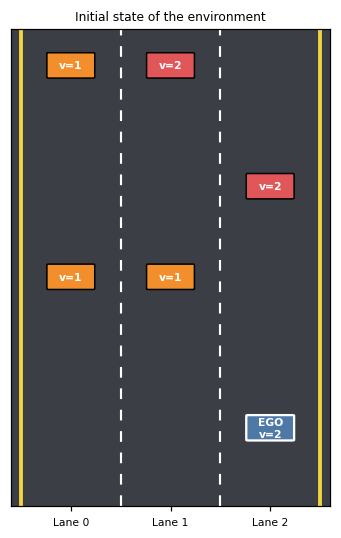

State id: 683 | lane: 2 | speed level: 2


In [3]:
def draw_scene(ax, snap, title="", action=None, crashed=False):
    ax.set_xlim(-0.6, 2.6); ax.set_ylim(-2.6, 13.2)
    ax.set_facecolor("#3b3f45"); ax.grid(False)
    for x in (0.5, 1.5):                                  # lane dividers
        ax.plot([x, x], [-2.6, 13.2], color="white", ls=(0, (5, 5)), lw=1.4)
    for x in (-0.5, 2.5):
        ax.plot([x, x], [-2.6, 13.2], color="#f5d442", lw=2.5)
    for lane, gap, spd in snap["cars"]:
        if -2.6 < gap < 13.2:
            col = "#f28e2b" if spd == 1 else "#e15759"
            ax.add_patch(FancyBboxPatch((lane - 0.22, gap - 0.4), 0.44, 0.8, boxstyle="round,pad=0.02", fc=col, ec="black"))
            ax.text(lane, gap, f"v={spd}", ha="center", va="center", fontsize=7, color="white", weight="bold")
    ex = "#d62728" if crashed else "#4e79a7"
    ax.add_patch(FancyBboxPatch((snap["lane"] - 0.22, -0.4), 0.44, 0.8, boxstyle="round,pad=0.02", fc=ex, ec="white", lw=1.5))
    ax.text(snap["lane"], 0, f"EGO\nv={snap['v']}", ha="center", va="center", fontsize=7, color="white", weight="bold")
    if crashed:
        ax.text(snap["lane"], 1.3, "CRASH", ha="center", color="yellow", fontsize=9, weight="bold")
    ax.set_xticks([0, 1, 2]); ax.set_xticklabels(["Lane 0", "Lane 1", "Lane 2"], fontsize=7)
    ax.set_yticks([])
    sub = f"\nlast action: {HighwayEnv.ACTION_NAMES[action]}" if action is not None else ""
    ax.set_title(title + sub, fontsize=8)

# --- Screenshot 1: a freshly reset environment
env_demo = HighwayEnv(np.random.default_rng(3))
env_demo.reset()
fig, ax = plt.subplots(figsize=(3.2, 5))
draw_scene(ax, env_demo.snapshot(), "Initial state of the environment")
plt.tight_layout(); plt.savefig("figures/env_initial.png", dpi=130); plt.show()
print("State id:", env_demo._obs(), "| lane:", env_demo.lane, "| speed level:", env_demo.v)

## 4. Algorithm – Q-Learning
**Working principle.** Q-Learning is a model-free, off-policy temporal-difference control algorithm. It learns the action-value function Q(s, a) – the expected discounted return when taking action *a* in state *s* and acting optimally afterwards – and stores it in a table of size |S| × |A| = 768 × 5. After every transition (s, a, r, s′):

**Q(s, a) ← Q(s, a) + α · [ r + γ · max<sub>a′</sub> Q(s′, a′) − Q(s, a) ]**

The bracket is the TD error. The target uses the *maximum* over next actions rather than the action actually taken, so the greedy policy learns the optimal behaviour even while the agent is exploring (off-policy). For a terminal state (crash) the target is just *r*.

**Behaviour policy – ε-greedy.** With probability ε a random action is chosen (exploration), otherwise argmax Q(s, ·) (exploitation). ε starts at 1.0 and decays exponentially to a floor.

**Why Q-Learning is suitable.**
* The state space (768) and action space (5) are small and discrete → a Q-table is enough, DQN would be unnecessary overhead.
* Model-free: the agent does not need to know the traffic dynamics, only experience.
* Off-policy: it can explore aggressively (crashes are cheap in simulation) while still converging to the optimal safe policy – unlike on-policy SARSA, which would learn a more conservative policy that accounts for its own random exploratory mistakes.
* The learned table is directly inspectable, which helps explain the driving behaviour.

In [4]:
class QLearningAgent:
    def __init__(self, n_states, n_actions, alpha, gamma, eps, eps_min, eps_decay, rng):
        self.q = np.zeros((n_states, n_actions))        # Q-table, all zeros
        self.n_actions = n_actions
        self.alpha, self.gamma = alpha, gamma
        self.eps, self.eps_min, self.eps_decay = eps, eps_min, eps_decay
        self.rng = rng

    def act(self, s, greedy=False):
        if not greedy and self.rng.random() < self.eps:           # explore
            return int(self.rng.integers(self.n_actions))
        best = np.flatnonzero(self.q[s] == self.q[s].max())       # exploit, random tie-break
        return int(self.rng.choice(best))

    def update(self, s, a, r, s_next, terminated):
        target = r if terminated else r + self.gamma * self.q[s_next].max()
        self.q[s, a] += self.alpha * (target - self.q[s, a])      # TD update

    def decay_epsilon(self):
        self.eps = max(self.eps_min, self.eps * self.eps_decay)

### 4.1 Training hyper-parameters

In [5]:
HP = dict(
    NUM_EPISODES = 20000,    # training episodes
    ALPHA        = 0.1,      # learning rate
    GAMMA        = 0.95,     # discount factor
    EPS_START    = 1.0,      # initial exploration
    EPS_MIN      = 0.02,     # minimum exploration
    EPS_DECAY    = 0.9997,   # multiplicative decay per episode
    MAX_STEPS    = HighwayEnv.MAX_STEPS,
    SEED         = 42,
    EVAL_EVERY   = 500,      # greedy evaluation checkpoint (episodes)
    EVAL_EPISODES= 100,
)
for k, v in HP.items():
    print(f"{k:14s} = {v}")
print("Number of episodes for eps to reach its floor:", int(np.log(HP['EPS_MIN']) / np.log(HP['EPS_DECAY'])))

NUM_EPISODES   = 20000
ALPHA          = 0.1
GAMMA          = 0.95
EPS_START      = 1.0
EPS_MIN        = 0.02
EPS_DECAY      = 0.9997
MAX_STEPS      = 200
SEED           = 42
EVAL_EVERY     = 500
EVAL_EPISODES  = 100
Number of episodes for eps to reach its floor: 13038


## 5. Training and evaluation functions
`run_episode` plays one episode; `evaluate_policy` runs the *greedy* policy (ε = 0, no learning) on fixed scenario seeds, which makes different agents directly comparable. During training the greedy policy is also evaluated every 500 episodes, so we can see the true quality of the learned policy without the noise of ε-exploration.

In [6]:
def evaluate_policy(policy, n_episodes, seed0):
    """policy(env, state) -> action. Each episode uses env seed seed0+i (same traffic for every agent)."""
    out = dict(reward=[], success=[], steps=[], speed=[], lane_changes=[], tailgate=[], overtakes=[], offroad=[])
    env = HighwayEnv(np.random.default_rng(0))
    for i in range(n_episodes):
        env.rng = np.random.default_rng(seed0 + i)
        s, tot = env.reset(), 0.0
        while True:
            s, r, term, trunc, _ = env.step(policy(env, s))
            tot += r
            if term or trunc: break
        out["reward"].append(tot); out["success"].append(0 if term else 1); out["steps"].append(env.t)
        out["speed"].append(env.stats["speed_sum"] / env.t)
        for k in ("lane_changes", "tailgate", "overtakes", "offroad"): out[k].append(env.stats[k])
    return {k: np.array(v) for k, v in out.items()}


def train(seed, n_episodes=HP["NUM_EPISODES"], verbose=True):
    env_rng, agent_rng = np.random.default_rng(seed), np.random.default_rng(seed + 1000)
    env = HighwayEnv(env_rng)
    agent = QLearningAgent(env.N_STATES, env.N_ACTIONS, HP["ALPHA"], HP["GAMMA"],
                           HP["EPS_START"], HP["EPS_MIN"], HP["EPS_DECAY"], agent_rng)
    H = dict(reward=np.zeros(n_episodes), success=np.zeros(n_episodes), speed=np.zeros(n_episodes),
             lane_changes=np.zeros(n_episodes), steps=np.zeros(n_episodes), eps=np.zeros(n_episodes),
             eval_ep=[], eval_success=[], eval_reward=[], log=[])
    t0 = time.time()
    for ep in range(n_episodes):
        s, total = env.reset(), 0.0
        while True:
            a = agent.act(s)
            s2, r, term, trunc, _ = env.step(a)
            agent.update(s, a, r, s2, term)               # learn from the transition
            s, total = s2, total + r
            if term or trunc: break
        H["eps"][ep] = agent.eps
        agent.decay_epsilon()
        H["reward"][ep], H["success"][ep] = total, 0 if term else 1
        H["speed"][ep] = env.stats["speed_sum"] / env.t
        H["lane_changes"][ep], H["steps"][ep] = env.stats["lane_changes"], env.t

        if (ep + 1) % HP["EVAL_EVERY"] == 0:              # greedy checkpoint
            ev = evaluate_policy(lambda e, st: agent.act(st, greedy=True), HP["EVAL_EPISODES"], 50000)
            H["eval_ep"].append(ep + 1); H["eval_success"].append(ev["success"].mean() * 100)
            H["eval_reward"].append(ev["reward"].mean())
        if (ep + 1) % 1000 == 0:
            sl = slice(ep - 999, ep + 1)
            line = (f"Ep {ep+1:5d}/{n_episodes} | reward {H['reward'][sl].mean():7.2f} | success {H['success'][sl].mean()*100:5.1f}% | "
                    f"speed {H['speed'][sl].mean():4.2f} | eps {agent.eps:5.3f} | greedy {H['eval_success'][-1]:5.1f}%")
            H["log"].append(line)
            if verbose: print(line)
    H["time"] = time.time() - t0
    return agent, H

## 6. Baseline agents
To judge whether the trained agent is really good we compare it with three reference drivers evaluated on identical traffic scenarios:

* **Random driver** – picks a random action each step.
* **Cautious driver** – always drives at speed 1 and never changes lane (safe but slow).
* **Reactive rule-based driver** – accelerates when the lane is free, brakes when a car is ≤3 cells ahead, never changes lane.

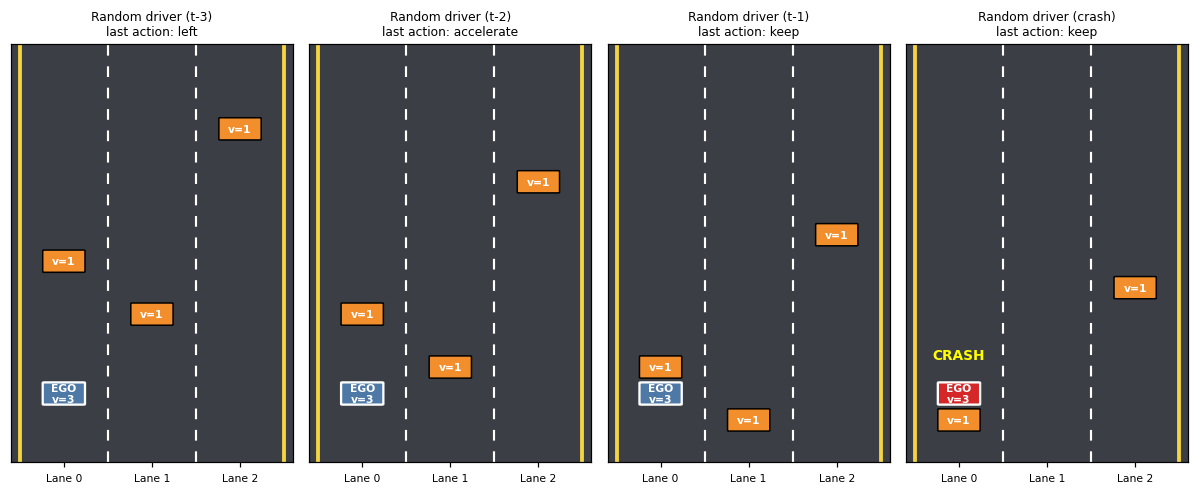

In [7]:
rand_rng = np.random.default_rng(7)
def random_policy(env, s):    return int(rand_rng.integers(env.N_ACTIONS))

def cautious_policy(env, s):                                        # settle at speed 1, never change lane
    return 2 if env.v > 1 else (1 if env.v < 1 else 0)

def reactive_policy(env, s):                                        # simple hand-written rule
    g = env._gap(env.lane)
    if g <= 3: return 2 if env.v > 1 else (1 if env.v < 1 else 0)   # slow to speed 1
    return 1 if env.v < 3 else 0

# --- Screenshot 2: what a random driver does (frames just before the crash)
env = HighwayEnv(np.random.default_rng(11)); frames = []
for attempt in range(50):
    s = env.reset(); frames = [(env.snapshot(), None, False)]
    while True:
        a = random_policy(env, s); s, r, term, trunc, info = env.step(a)
        frames.append((env.snapshot(), a, info["crashed"]))
        if term or trunc: break
    if term: break
last = frames[-4:]
fig, axes = plt.subplots(1, 4, figsize=(11, 4.6))
for ax, (snap, a, cr), k in zip(axes, last, range(-3, 1)):
    draw_scene(ax, snap, f"Random driver (t-{-k})" if k < 0 else "Random driver (crash)", a, cr)
plt.tight_layout(); plt.savefig("figures/random_agent_crash.png", dpi=130); plt.show()

## 7. Training the agent

In [8]:
print(f"Training Q-Learning agent for {HP['NUM_EPISODES']} episodes (seed {HP['SEED']}) ...\n")
agent, H = train(HP["SEED"])
print(f"\nTraining finished in {H['time']:.1f} s | Q-table shape: {agent.q.shape}")
print(f"States visited at least once: {(np.abs(agent.q).sum(axis=1) > 0).sum()} / {agent.q.shape[0]}")

Training Q-Learning agent for 20000 episodes (seed 42) ...



Ep  1000/20000 | reward  -39.77 | success   7.3% | speed 2.01 | eps 0.741 | greedy  98.0%


Ep  2000/20000 | reward  -23.76 | success   8.9% | speed 1.93 | eps 0.549 | greedy  98.0%


Ep  3000/20000 | reward    0.04 | success  15.7% | speed 1.93 | eps 0.407 | greedy  99.0%


Ep  4000/20000 | reward   16.69 | success  18.7% | speed 2.04 | eps 0.301 | greedy 100.0%


...

Ep 16000/20000 | reward  158.67 | success  67.0% | speed 2.28 | eps 0.020 | greedy 100.0%


Ep 17000/20000 | reward  162.62 | success  66.1% | speed 2.33 | eps 0.020 | greedy 100.0%


Ep 18000/20000 | reward  155.92 | success  63.5% | speed 2.36 | eps 0.020 | greedy 100.0%


Ep 19000/20000 | reward  156.24 | success  62.9% | speed 2.34 | eps 0.020 | greedy 100.0%


Ep 20000/20000 | reward  162.68 | success  65.5% | speed 2.36 | eps 0.020 | greedy 100.0%

Training finished in 99.8 s | Q-table shape: (768, 5)
States visited at least once: 755 / 768


In [9]:
# Save a "console screenshot" of the training log (used in the report)
def console_image(lines, fname, fs=9):
    wid = max(len(l) for l in lines) * fs * 0.62 / 72 + 0.4
    h = 0.30 * len(lines) + 0.5
    fig = plt.figure(figsize=(wid, h), facecolor="#1e1e1e")
    fig.text(0.01, 0.98, "\n".join(lines), family="monospace", color="#d4d4d4", fontsize=fs, va="top")
    plt.savefig(fname, dpi=130, facecolor="#1e1e1e", bbox_inches="tight", pad_inches=0.15); plt.close(fig)

hdr = [f"$ python train.py  # Q-Learning, {HP['NUM_EPISODES']} episodes, seed {HP['SEED']}", ""]
console_image(hdr + H["log"][:6] + ["  ..."] + H["log"][-3:] + ["", f"Training finished in {H['time']:.1f} s"], "figures/training_console.png")

## 8. Results and learning curve
### 8.1 Reward vs. Episodes

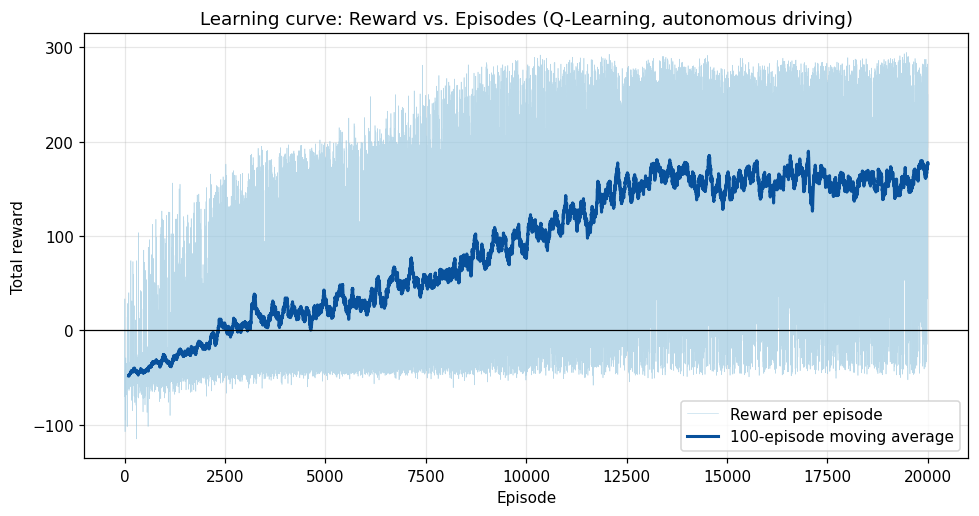

Average reward - first 100 episodes :   -48.37
Average reward - last 100 episodes  :   177.12  (eps-greedy, eps = 0.02)
Success rate  - first 100 episodes :    6.0 %
Success rate  - last 100 episodes  :   77.0 %  (eps-greedy)
First episode where 100-ep average reward > 0 : 2330
First checkpoint with greedy success >= 95 %  : 1000


In [10]:
def moving_avg(x, w): return np.convolve(x, np.ones(w) / w, mode="valid")
W = 100
ep_axis = np.arange(1, HP["NUM_EPISODES"] + 1)
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(ep_axis, H["reward"], color="#9ecae1", lw=0.4, alpha=0.7, label="Reward per episode")
ax.plot(ep_axis[W-1:], moving_avg(H["reward"], W), color="#08519c", lw=2, label=f"{W}-episode moving average")
ax.axhline(0, color="k", lw=0.8)
ax.set_xlabel("Episode"); ax.set_ylabel("Total reward"); ax.set_title("Learning curve: Reward vs. Episodes (Q-Learning, autonomous driving)")
ax.legend(loc="lower right"); plt.tight_layout(); plt.savefig("figures/learning_curve.png", dpi=130); plt.show()

print(f"Average reward - first 100 episodes : {H['reward'][:100].mean():8.2f}")
print(f"Average reward - last 100 episodes  : {H['reward'][-100:].mean():8.2f}  (eps-greedy, eps = {HP['EPS_MIN']})")
print(f"Success rate  - first 100 episodes : {H['success'][:100].mean()*100:6.1f} %")
print(f"Success rate  - last 100 episodes  : {H['success'][-100:].mean()*100:6.1f} %  (eps-greedy)")
first95 = next((int(e) for e, v in zip(H['eval_ep'], H['eval_success']) if v >= 95), None)
ma = moving_avg(H["reward"], W); first_pos = int(np.argmax(ma > 0)) + W
print(f"First episode where {W}-ep average reward > 0 : {first_pos}")
print(f"First checkpoint with greedy success >= 95 %  : {first95}")

### 8.2 Success rate, average speed and exploration
The training success rate (blue) is measured *while exploring* with ε-greedy, so a random move can still cause a crash. The orange line is the greedy policy (ε = 0) evaluated on 100 fresh scenarios every 500 episodes, i.e. the real quality of the learned driving policy.

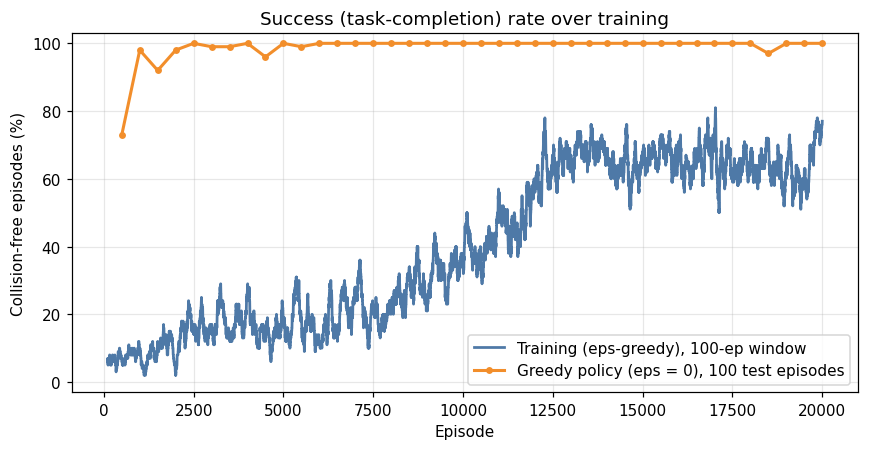

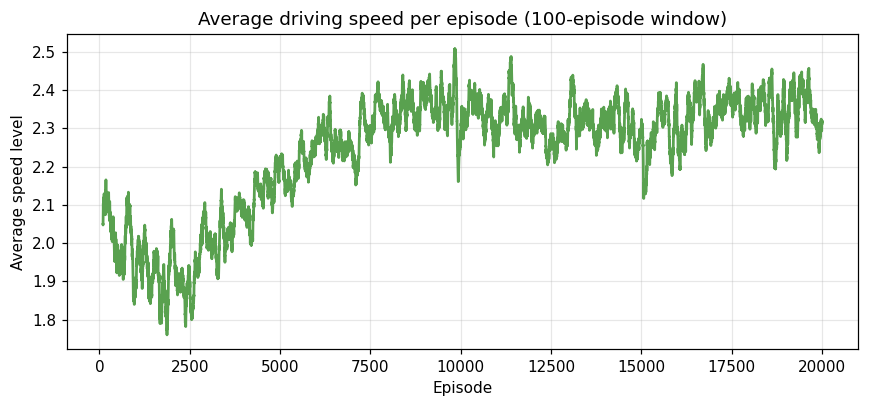

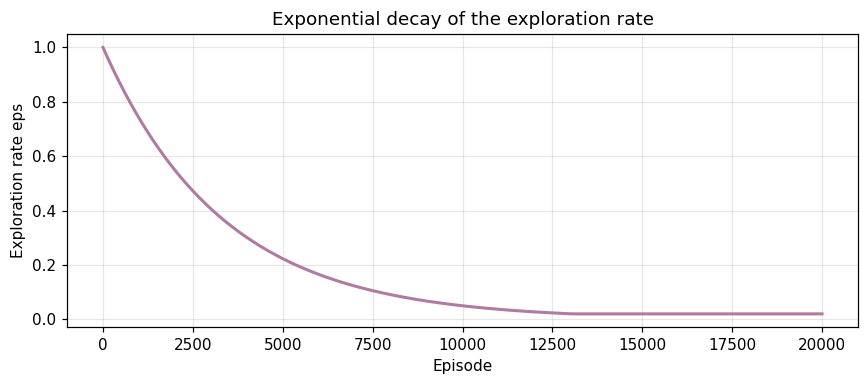

In [11]:
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(ep_axis[W-1:], moving_avg(H["success"], W) * 100, color="#4e79a7", lw=1.8, label="Training (eps-greedy), 100-ep window")
ax.plot(H["eval_ep"], H["eval_success"], color="#f28e2b", lw=2, marker="o", ms=3.5, label="Greedy policy (eps = 0), 100 test episodes")
ax.set_xlabel("Episode"); ax.set_ylabel("Collision-free episodes (%)"); ax.set_ylim(-3, 103)
ax.set_title("Success (task-completion) rate over training"); ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig("figures/success_rate_curve.png", dpi=130); plt.show()

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(ep_axis[W-1:], moving_avg(H["speed"], W), color="#59a14f", lw=1.8)
ax.set_xlabel("Episode"); ax.set_ylabel("Average speed level"); ax.set_title("Average driving speed per episode (100-episode window)")
plt.tight_layout(); plt.savefig("figures/speed_curve.png", dpi=130); plt.show()

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(ep_axis, H["eps"], color="#b07aa1", lw=2)
ax.set_xlabel("Episode"); ax.set_ylabel("Exploration rate eps"); ax.set_title("Exponential decay of the exploration rate")
plt.tight_layout(); plt.savefig("figures/epsilon_decay.png", dpi=130); plt.show()

### 8.3 Performance in training phases

In [12]:
block = HP["NUM_EPISODES"] // 5
rows = []
print(f"{'Episodes':>13} | {'Avg reward':>10} | {'Success %':>9} | {'Avg speed':>9} | {'Lane chg / ep':>13}")
print("-" * 66)
for b in range(5):
    sl = slice(b * block, (b + 1) * block)
    row = (f"{b*block+1}-{(b+1)*block}", H["reward"][sl].mean(), H["success"][sl].mean() * 100, H["speed"][sl].mean(), H["lane_changes"][sl].mean())
    rows.append(row)
    print(f"{row[0]:>13} | {row[1]:10.2f} | {row[2]:9.1f} | {row[3]:9.2f} | {row[4]:13.2f}")

     Episodes | Avg reward | Success % | Avg speed | Lane chg / ep
------------------------------------------------------------------
       1-4000 |     -11.70 |      12.7 |      1.98 |         14.28
    4001-8000 |      36.33 |      18.3 |      2.23 |         14.53
   8001-12000 |      99.95 |      37.5 |      2.34 |         19.51
  12001-16000 |     158.24 |      65.8 |      2.30 |         29.72
  16001-20000 |     159.37 |      64.5 |      2.35 |         29.45


## 9. Final evaluation of the trained agent
The greedy policy (ε = 0) is tested on **1,000 new episodes** whose traffic seeds were never used in training, and compared against the three baseline drivers on exactly the same scenarios.

In [13]:
N_EVAL, SEED_EVAL = 1000, 90000
results = {
    "Random driver":        evaluate_policy(random_policy, N_EVAL, SEED_EVAL),
    "Cautious (speed 1)":   evaluate_policy(cautious_policy, N_EVAL, SEED_EVAL),
    "Reactive rule-based":  evaluate_policy(reactive_policy, N_EVAL, SEED_EVAL),
    "Q-Learning agent":     evaluate_policy(lambda e, s: agent.act(s, greedy=True), N_EVAL, SEED_EVAL),
}
final_lines = [f"Greedy evaluation, {N_EVAL} unseen episodes (200 steps max)", "",
               f"{'Agent':21s}{'Succ%':>7}{'Reward':>9}{'Std':>8}{'Speed':>7}{'LaneCh':>8}{'Unsafe':>8}{'Overtk':>8}"]
for name, o in results.items():
    final_lines.append(f"{name:21s}{o['success'].mean()*100:7.1f}{o['reward'].mean():9.2f}{o['reward'].std():8.2f}"
                       f"{o['speed'].mean():7.2f}{o['lane_changes'].mean():8.2f}{o['tailgate'].mean():8.2f}{o['overtakes'].mean():8.2f}")
print("\n".join(final_lines))
console_image(["$ python evaluate.py"] + [""] + final_lines, "figures/final_results_console.png")

Greedy evaluation, 1000 unseen episodes (200 steps max)

Agent                  Succ%   Reward     Std  Speed  LaneCh  Unsafe  Overtk
Random driver            8.7   -47.40   20.33   2.00   10.62    0.56    0.75
Cautious (speed 1)     100.0   100.00    0.00   1.00    0.00    0.00    0.00
Reactive rule-based    100.0    62.47  111.38   1.27    0.00   64.27    1.40
Q-Learning agent       100.0   216.67   56.62   2.26   29.54    3.05   18.98


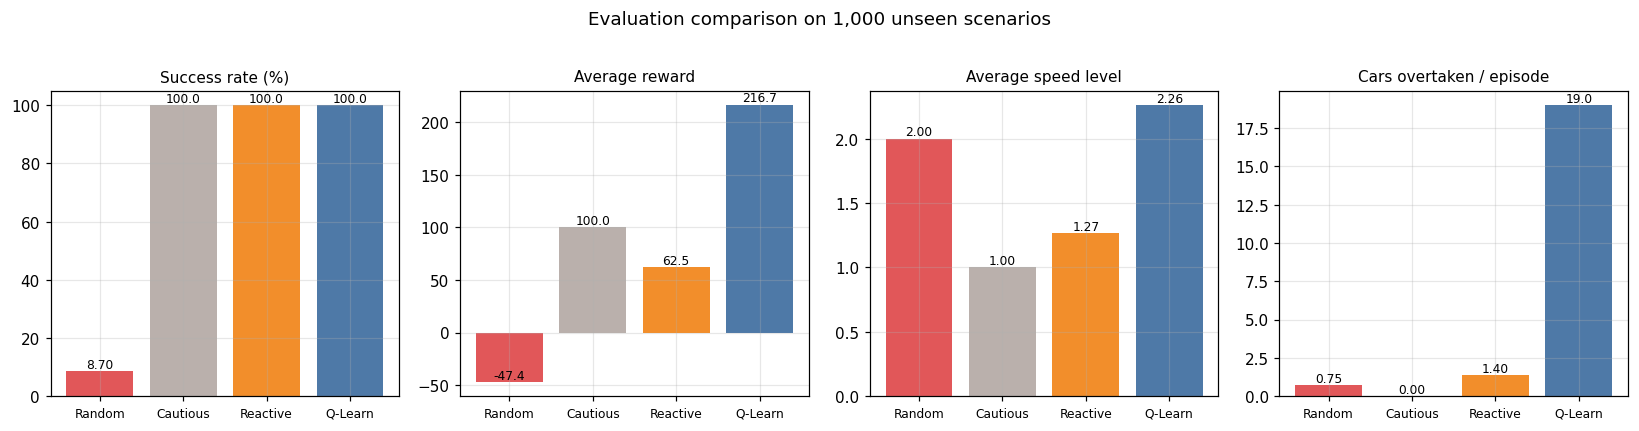

In [14]:
names = list(results); colors = ["#e15759", "#bab0ac", "#f28e2b", "#4e79a7"]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
for ax, (key, title, scale) in zip(axes, [("success", "Success rate (%)", 100), ("reward", "Average reward", 1),
                                         ("speed", "Average speed level", 1), ("overtakes", "Cars overtaken / episode", 1)]):
    vals = [results[n][key].mean() * scale for n in names]
    ax.bar(range(4), vals, color=colors)
    for i, v in enumerate(vals): ax.text(i, v, f"{v:.1f}" if abs(v) >= 10 else f"{v:.2f}", ha="center", va="bottom", fontsize=8)
    ax.set_xticks(range(4)); ax.set_xticklabels(["Random", "Cautious", "Reactive", "Q-Learn"], fontsize=8)
    ax.set_title(title, fontsize=10)
plt.suptitle("Evaluation comparison on 1,000 unseen scenarios", y=1.02); plt.tight_layout()
plt.savefig("figures/evaluation_comparison.png", dpi=130, bbox_inches="tight"); plt.show()

## 10. Robustness – training with several random seeds
Because the traffic is random, a single run could be lucky. The same experiment is repeated with 5 seeds (the main seed 42 plus 4 more); each trained agent is evaluated greedily on the same 1,000 unseen scenarios.

seed 1 trained in 99.1 s


seed 2 trained in 103.8 s


seed 3 trained in 104.1 s


seed 4 trained in 99.3 s

 Seed | Success % | Avg reward | Avg speed
--------------------------------------------


   42 |     100.0 |     216.67 |      2.26


    1 |     100.0 |     207.98 |      2.18


    2 |     100.0 |     211.64 |      2.20


    3 |     100.0 |     214.90 |      2.22


    4 |     100.0 |     212.67 |      2.24
--------------------------------------------
 mean |     100.0 |     212.77 |      2.22
  std |       0.0 |       2.96 |      0.03


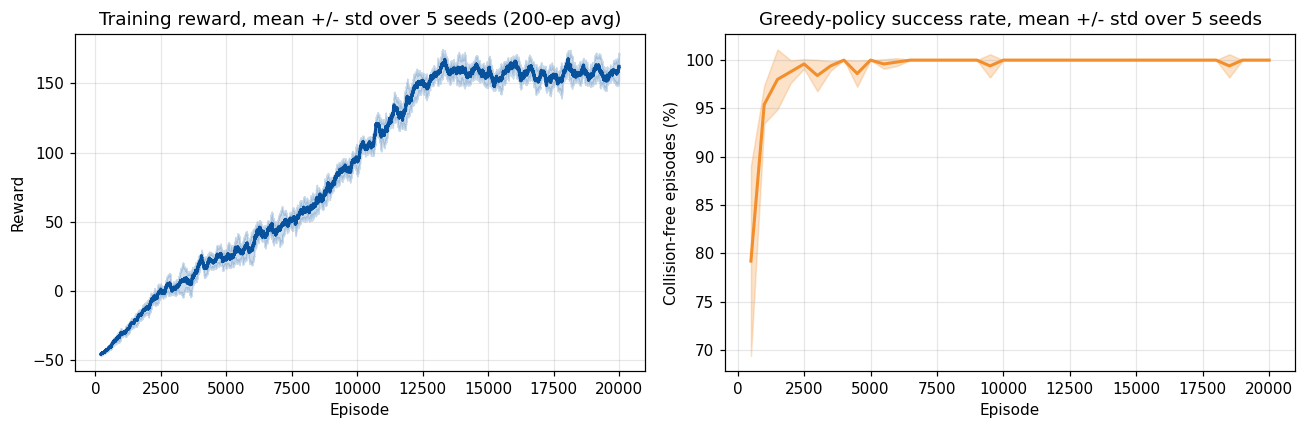

In [15]:
seeds = [42, 1, 2, 3, 4]
runs = {42: (agent, H)}
for sd in seeds[1:]:
    runs[sd] = train(sd, verbose=False)
    print(f"seed {sd} trained in {runs[sd][1]['time']:.1f} s")

seed_rows = []
print(f"\n{'Seed':>5} | {'Success %':>9} | {'Avg reward':>10} | {'Avg speed':>9}")
print("-" * 44)
for sd in seeds:
    ag, _ = runs[sd]
    ev = evaluate_policy(lambda e, s, ag=ag: ag.act(s, greedy=True), N_EVAL, SEED_EVAL)
    seed_rows.append((sd, ev["success"].mean() * 100, ev["reward"].mean(), ev["speed"].mean()))
    print(f"{sd:>5} | {seed_rows[-1][1]:9.1f} | {seed_rows[-1][2]:10.2f} | {seed_rows[-1][3]:9.2f}")
arr = np.array([r[1:] for r in seed_rows])
print("-" * 44); print(f"{'mean':>5} | {arr[:,0].mean():9.1f} | {arr[:,1].mean():10.2f} | {arr[:,2].mean():9.2f}")
print(f"{'std':>5} | {arr[:,0].std():9.1f} | {arr[:,1].std():10.2f} | {arr[:,2].std():9.2f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
M = np.array([moving_avg(runs[sd][1]["reward"], 200) for sd in seeds]); x = np.arange(200, HP["NUM_EPISODES"] + 1)
axes[0].plot(x, M.mean(0), color="#08519c", lw=2); axes[0].fill_between(x, M.mean(0) - M.std(0), M.mean(0) + M.std(0), color="#08519c", alpha=0.2)
axes[0].set_title("Training reward, mean +/- std over 5 seeds (200-ep avg)"); axes[0].set_xlabel("Episode"); axes[0].set_ylabel("Reward")
E = np.array([runs[sd][1]["eval_success"] for sd in seeds]); xe = runs[42][1]["eval_ep"]
axes[1].plot(xe, E.mean(0), color="#f28e2b", lw=2); axes[1].fill_between(xe, E.mean(0) - E.std(0), E.mean(0) + E.std(0), color="#f28e2b", alpha=0.25)
axes[1].set_title("Greedy-policy success rate, mean +/- std over 5 seeds"); axes[1].set_xlabel("Episode"); axes[1].set_ylabel("Collision-free episodes (%)")
plt.tight_layout(); plt.savefig("figures/multi_seed.png", dpi=130); plt.show()

## 11. Demonstration – the trained agent driving
First, one episode of the trained agent is plotted as lane and speed over time, then the frames around a typical **overtaking manoeuvre** are shown.

Demo episode seed 375: 200 steps, total reward 292.7, overtakes 34, lane changes 24, avg speed 2.98


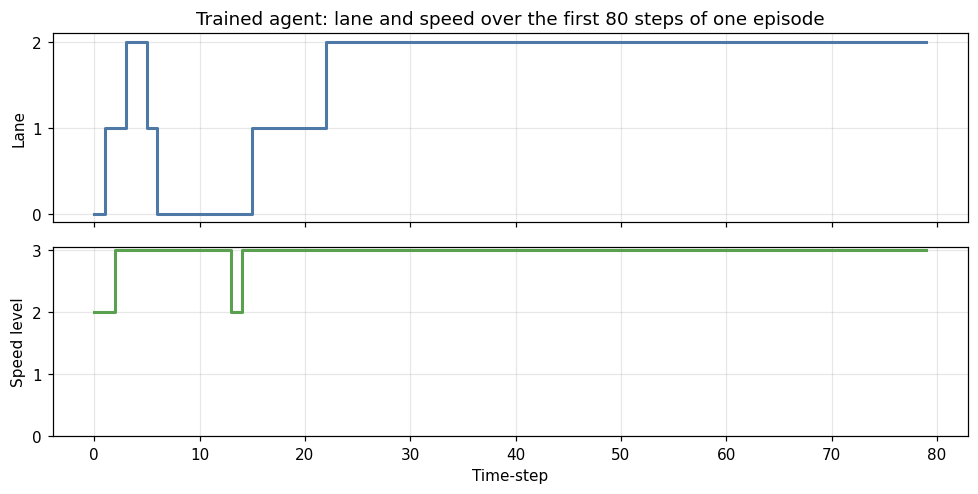

In [16]:
def rollout(agent, seed, greedy=True):
    env = HighwayEnv(np.random.default_rng(seed)); s = env.reset()
    frames, acts, rews = [(env.snapshot(), None, False)], [], []
    while True:
        a = agent.act(s, greedy=greedy); s, r, term, trunc, info = env.step(a)
        frames.append((env.snapshot(), a, info["crashed"])); acts.append(a); rews.append(r)
        if term or trunc: break
    return env, frames, acts, rews

# pick a representative demo episode: collision-free, high reward, several overtakes, a handful of lane changes
cands = []
for seed in range(200, 400):
    e_, f_, a_, r_ = rollout(agent, seed)
    if e_.t == 200 and 3 <= e_.stats["lane_changes"] <= 25 and e_.stats["overtakes"] >= 8:
        cands.append((sum(r_), seed))
best_seed = max(cands)[1] if cands else 200
env_d, frames, acts, rews = rollout(agent, best_seed)
print(f"Demo episode seed {best_seed}: {env_d.t} steps, total reward {sum(rews):.1f}, overtakes {env_d.stats['overtakes']}, "
      f"lane changes {env_d.stats['lane_changes']}, avg speed {env_d.stats['speed_sum']/env_d.t:.2f}")

T = 80
lanes = [f[0]["lane"] for f in frames[:T]]; spd = [f[0]["v"] for f in frames[:T]]
fig, axes = plt.subplots(2, 1, figsize=(9, 4.6), sharex=True)
axes[0].step(range(T), lanes, where="post", color="#4e79a7", lw=2); axes[0].set_yticks([0, 1, 2]); axes[0].set_ylabel("Lane")
axes[0].set_title("Trained agent: lane and speed over the first 80 steps of one episode")
axes[1].step(range(T), spd, where="post", color="#59a14f", lw=2); axes[1].set_yticks([0, 1, 2, 3]); axes[1].set_ylabel("Speed level"); axes[1].set_xlabel("Time-step")
plt.tight_layout(); plt.savefig("figures/trajectory.png", dpi=130); plt.show()

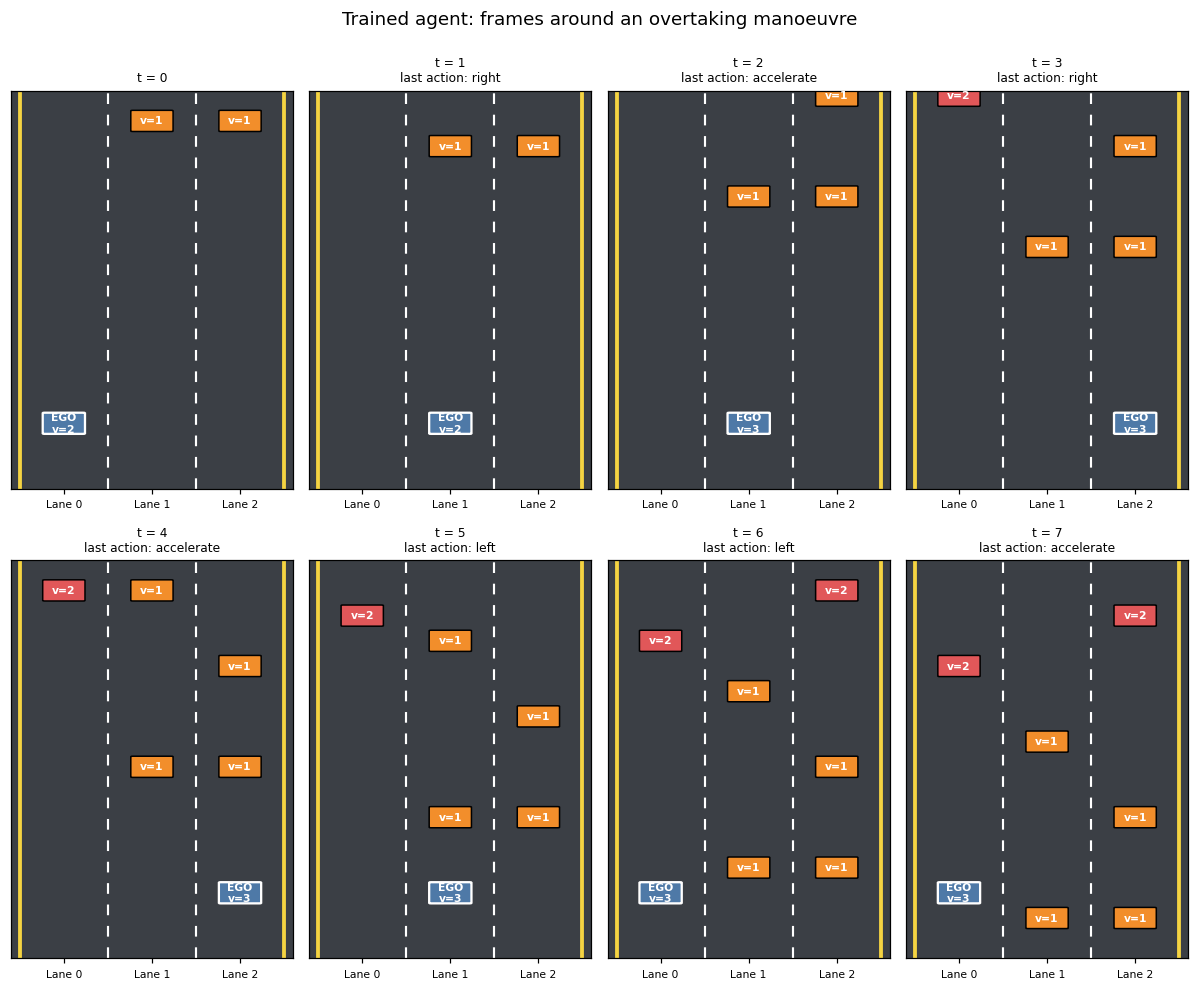

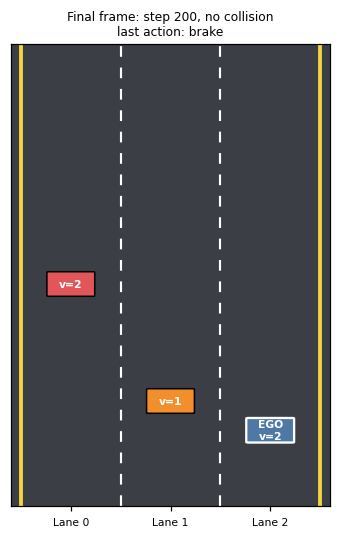

In [17]:
# first lane change in the demo episode -> show 8 consecutive frames around it
first_lc = next(i for i, a in enumerate(acts) if a in (3, 4))
start = max(0, first_lc - 3)
fig, axes = plt.subplots(2, 4, figsize=(11, 9))
for ax, idx in zip(axes.ravel(), range(start, start + 8)):
    snap, a, cr = frames[idx]
    draw_scene(ax, snap, f"t = {snap['t']}", a, cr)
plt.suptitle("Trained agent: frames around an overtaking manoeuvre", y=0.995); plt.tight_layout()
plt.savefig("figures/trained_montage.png", dpi=120); plt.show()

# final frame of a complete episode
fig, ax = plt.subplots(figsize=(3.2, 5))
draw_scene(ax, frames[-1][0], f"Final frame: step {env_d.t}, no collision", frames[-1][1], frames[-1][2])
plt.tight_layout(); plt.savefig("figures/final_frame.png", dpi=130); plt.show()

### 11.1 What did the agent learn? (policy inspection)
The table shows the greedy action chosen when the ego car is in the middle lane at medium speed, as a function of the distance bucket of the car ahead in the *own* lane and whether the left lane is free (*free* = nothing within 6 cells).

In [18]:
names_b = ["critical (<=1)", "near (2-3)", "medium (4-6)", "free (>=7)"]
def state_id(lane, vi, b0, b1, b2):
    s = lane * 4 + vi
    for b in (b0, b1, b2): s = s * 4 + b
    return s
print("Ego: lane 1, speed level 2 (medium). Right lane assumed free.\n")
print(f"{'car ahead (own lane)':22s} | {'left lane free':>15} | {'left lane blocked (near)':>25}")
print("-" * 68)
for b in range(4):
    a_free = HighwayEnv.ACTION_NAMES[int(np.argmax(agent.q[state_id(1, 2, 3, b, 3)]))]
    a_blk  = HighwayEnv.ACTION_NAMES[int(np.argmax(agent.q[state_id(1, 2, 1, b, 3)]))]
    print(f"{names_b[b]:22s} | {a_free:>15} | {a_blk:>25}")

Ego: lane 1, speed level 2 (medium). Right lane assumed free.

car ahead (own lane)   |  left lane free |  left lane blocked (near)
--------------------------------------------------------------------
critical (<=1)         |           right |                     right
near (2-3)             |           right |                     right
medium (4-6)           |            left |                accelerate
free (>=7)             |      accelerate |                accelerate


## 12. Performance analysis, observations and conclusion
The numerical values below are the ones printed by the cells above (main run, seed 42).

* **Does performance improve with training?** Yes. The 100-episode average reward rises from −48.4 (first 100 episodes) to +177.1 (last 100 episodes) and crosses zero at about episode 2,330. The collision-free rate of the greedy policy rises from about three quarters at the first checkpoint (episode 500) to 100 % from about episode 5,000 onwards.
* **Training behaviour.** Safe driving is learned quickly (greedy success ≥ 95 % after ≈ 1,000 episodes), but *efficient* driving takes much longer: reward keeps climbing until ε reaches its floor at ≈ 13,000 episodes and then plateaus at ≈ 160–180. Learning is slow at first because the −50 crash penalty is only discovered by chance, then speeds up as the values propagate backwards through the Q-table.
* **Agent vs. baselines (1,000 unseen scenarios).** Random driver: 8.7 % collision-free, reward −47.4. Cautious driver: 100 % safe but only 100.0 reward because it crawls at speed 1. Reactive rule-based driver: 100 % safe, 62.5 reward – it gets stuck behind slow cars (≈ 64 unsafe-gap steps per episode). Q-Learning agent: 100 % collision-free, **216.7 reward**, average speed 2.26 and ≈ 19 cars overtaken per episode – it is the only agent that learned to use lane changes productively.
* **Role of ε.** The training-time success rate (≈ 65–77 %) is lower than the greedy success rate (100 %) because 2 % random actions at high speed can still cause crashes. These crashes are caused by exploration, not by the learned policy.
* **Robustness.** Over 5 seeds the greedy agent is collision-free in every test episode and obtains a mean reward of 212.8 ± 3.0.
* **Design note.** In a first version of the simulator the minimum ego speed equalled the speed of the slowest cars, so the agent could get boxed in by three slow cars side by side and never escape (a physical dead-lock, not a learning failure). Allowing the ego car to stop (speed level 0) removed these cases.
* **Limitations.** (i) The environment is a simplified 1-D simulator, not a physics-based one; (ii) the discretised state ignores the speed of other cars; (iii) a Q-table grows exponentially with the number of state variables – continuous sensor inputs (camera/LiDAR) would require function approximation such as DQN.
* **Possible extensions:** compare with SARSA and DQN, add the lead car's speed to the state, more lanes and denser traffic, or use the `highway-env` simulator.

### Conclusion
A tabular Q-Learning agent was trained from scratch to drive on a stochastic three-lane highway. After 20,000 training episodes the greedy policy completed the 200-step drive without a collision in all 1,000 unseen test scenarios and earned more than twice the reward of the cautious baseline (216.7 vs. 100.0), and the result is stable across 5 random seeds. A sparse crash penalty combined with a dense progress reward was enough for the agent to discover safe driving behaviour: keeping a safe gap, stopping or slowing before slow traffic, and overtaking via lane changes.

### References
1. R. S. Sutton and A. G. Barto, *Reinforcement Learning: An Introduction*, 2nd ed., MIT Press, 2018.
2. C. J. C. H. Watkins and P. Dayan, "Q-learning," *Machine Learning*, 8(3-4), 279–292, 1992.
3. E. Leurent, *An Environment for Autonomous Driving Decision-Making* (highway-env), GitHub, 2018 – inspiration for the multi-lane highway task.
4. B. R. Kiran et al., "Deep Reinforcement Learning for Autonomous Driving: A Survey," *IEEE Trans. on Intelligent Transportation Systems*, 2022.